# Entrenamiento de Faster R-CNN v2

Partimos de los pesos de COCO y ajustamos todas las capas con el conjunto que indiques abajo. En cada época medimos el mAP en validación.

## Datos

Pon la ruta de tu dataset. La carpeta debe contener `images/train/`, `images/val/`, `annotations/instances_train.json` y `annotations/instances_val.json`.

In [1]:
from pathlib import Path

data_dir = Path("/home/lvcks/Documents/CUARTO/VISION1/PRACTICAS/P5/parasite-detection-benchmark/data/preprocessed/parasites-1s07h-dedup")

## Parámetros

Cambia aquí el número de épocas, el tamaño del lote o la tasa de aprendizaje. Usa otro `run_name` para guardar un experimento aparte.

El warmup empieza en `learning_rate * start_factor` y termina en `learning_rate * end_factor`. `warmup_batches` indica el máximo de lotes de warmup y se limita a los lotes de la primera época menos uno. Después el learning rate baja siguiendo una curva coseno hasta cero al terminar las épocas previstas.

In [2]:
from parasite_detection.faster_rcnn import TrainConfig, train_model

config = TrainConfig(
    data_dir=data_dir,
    run_name="baseline",

    # entrenamiento
    epochs=20,
    batch_size=2,

    # optimizador sgd
    learning_rate=0.0025,
    momentum=0.9,
    weight_decay=0.0005,

    # warmup antes del descenso coseno
    start_factor=0.001,
    end_factor=1.0,
    warmup_batches=1000,

    # tamaño de entrada
    image_size=640,

    # cero desactiva la parada temprana
    patience=10,

    # semilla
    seed=42,
)

## Entrenamiento

Esta celda muestra el progreso por lote y registra `train_loss`, `val_loss`, `map`, `map50` y `lr` por época. Al terminar, `model` contiene los pesos de la época con mayor mAP en validación. Los checkpoints se guardan en `models/trained/fasterrcnn_v2/<run_name>/` y las métricas y parámetros en `results/metrics/fasterrcnn_v2/<run_name>/`.

In [3]:
model, history = train_model(config)

Dispositivo: cuda | Train: 1157 | Val: 215


Época 1/20:   0%|          | 0/579 [00:00<?, ?lote/s]

Pérdida de validación:   0%|          | 0/108 [00:00<?, ?lote/s]

Evaluación:   0%|          | 0/108 [00:00<?, ?lote/s]

Época 1/20 | train loss 0.5610 | val loss 0.2511 | mAP 0.3935 | mAP50 0.5404 | lr 0.002500


Época 2/20:   0%|          | 0/579 [00:00<?, ?lote/s]

... (71 outputs left out)

Época 20/20:   0%|          | 0/579 [00:00<?, ?lote/s]

Pérdida de validación:   0%|          | 0/108 [00:00<?, ?lote/s]

Evaluación:   0%|          | 0/108 [00:00<?, ?lote/s]

Época 20/20 | train loss 0.0371 | val loss 0.1685 | mAP 0.6531 | mAP50 0.8006 | lr 0.000015
Mejor época: 16 | mAP 0.6633 | /home/lvcks/Documents/CUARTO/VISION1/PRACTICAS/P5/parasite-detection-benchmark/models/trained/fasterrcnn_v2/baseline/best_model.pth


In [6]:
%config InlineBackend.figure_format = "retina"

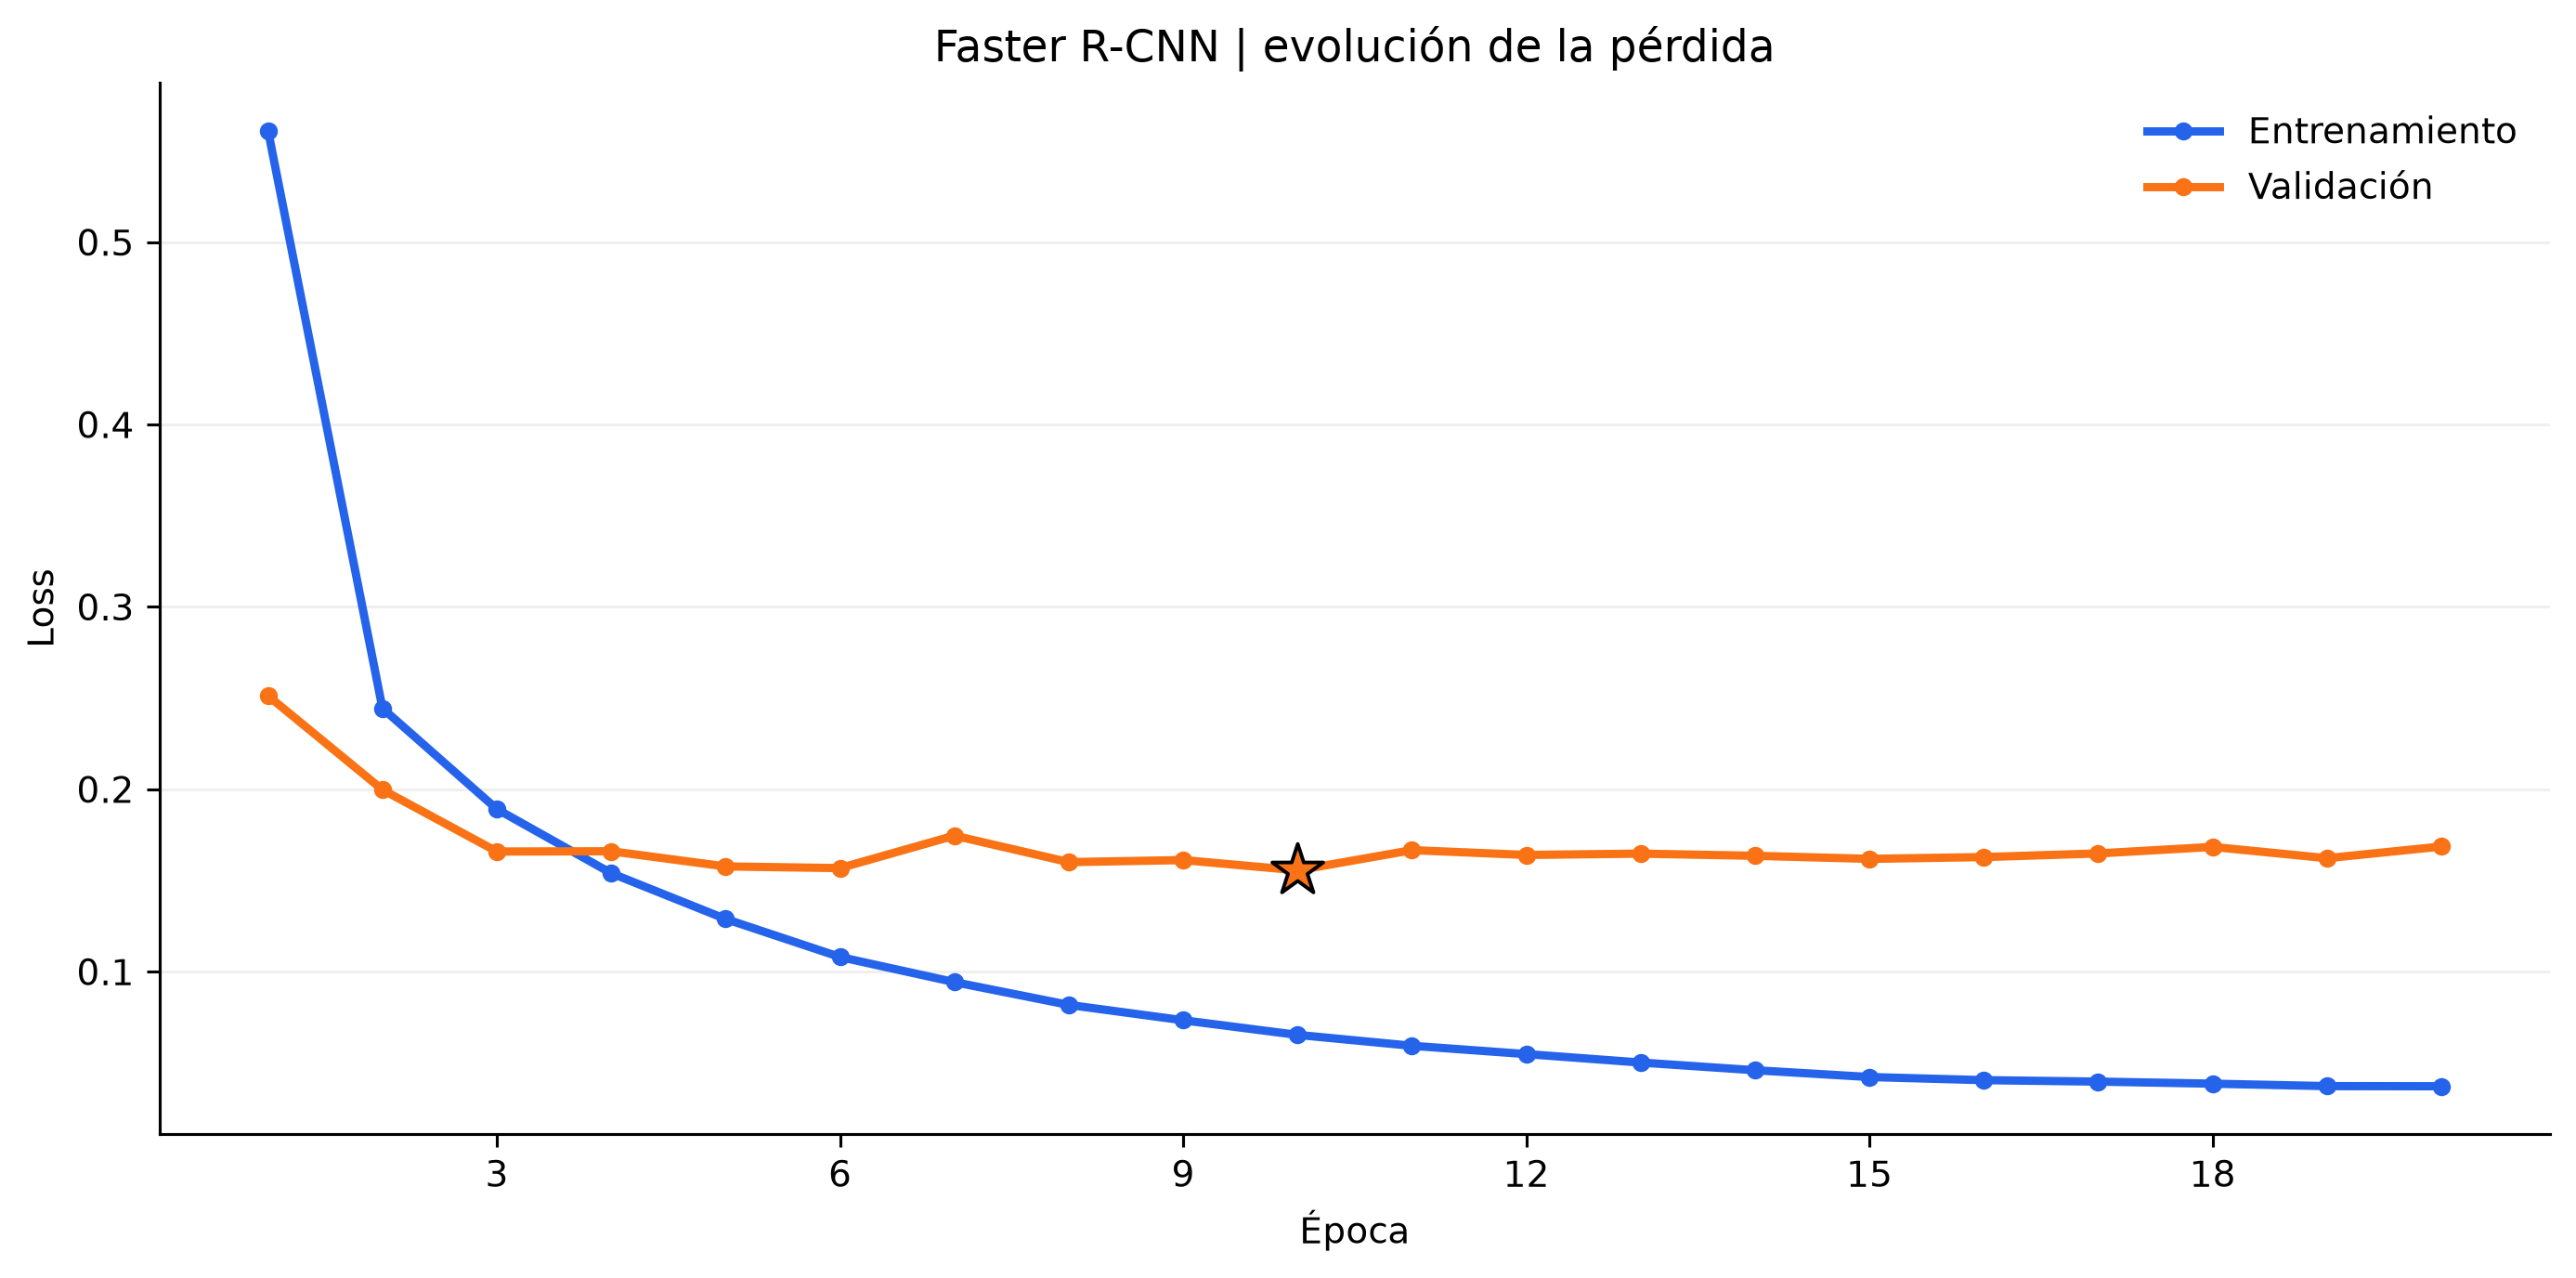

In [7]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

df = pd.DataFrame(history).sort_values("epoch")

fig, ax = plt.subplots(figsize=(10, 5), dpi=140)

# dibujamos las pérdidas de cada época
ax.plot(
    df["epoch"], df["train_loss"],
    color="#2563eb", marker="o", markersize=4,
    linewidth=2.3, label="Entrenamiento",
)
ax.plot(
    df["epoch"], df["val_loss"],
    color="#f97316", marker="o", markersize=4,
    linewidth=2.3, label="Validación",
)

# destacamos la época con menor pérdida de validación
best = df.loc[df["val_loss"].idxmin()]
ax.scatter(
    best["epoch"], best["val_loss"],
    color="#f97316", edgecolor="black",
    marker="*", s=220, zorder=5,
)

# ajustamos el aspecto de la figura
ax.set(title="Faster R-CNN | evolución de la pérdida", xlabel="Época", ylabel="Loss")
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.grid(axis="y", alpha=0.2)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
fig.tight_layout()
plt.show()